# TremorLens: Exploratory Data Analysis (Part 1)

Data comes from our PostgreSQL database (Neon), loaded by the ETL pipeline in `etl/`.

| Table | Meaning |
|---|---|
| `usgs_events` | validated USGS events, M >= 4.5, 2000 to 2026 (main source, complete for the whole period) |
| `emsc_events` | validated EMSC events (second source, coverage grows over time) |
| `events_clean` | reconciled table: each event is labelled `both`, `usgs_only` or `emsc_only` |
| `rejected_records` | records that failed Pydantic validation, with the reason |
| `ingest_runs` | one log row per pipeline run |

**Sections in this part:** 1 load and overview, 2 data quality and source coverage, 3 depth, 4 Gutenberg-Richter law, 5 time patterns and aftershocks.
Part 2 will cover maps, Pakistan and the Hindu Kush, and the USGS vs EMSC comparison.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text

# project root = first parent folder that has requirements.txt
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
engine = create_engine(os.environ["DATABASE_URL"])

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def q(sql):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()


print("project root:", ROOT)
print("figures go to:", FIG)

project root: d:\Project1\tremorlens
figures go to: d:\Project1\tremorlens\reports\figures


## 1. Load and overview

In [2]:
usgs = q("""SELECT event_id, event_time, latitude, longitude, depth_km, magnitude,
                 mag_type, place, felt, cdi, mmi, sig FROM usgs_events""")
clean = q("""SELECT event_id, source, event_time, latitude, longitude, depth_km, magnitude,
                  mag_type, depth_is_default FROM events_clean""")

for df in (usgs, clean):
    df["event_time"] = pd.to_datetime(df["event_time"], utc=True)
    df["year"] = df["event_time"].dt.year
    df["mag_type"] = df["mag_type"].astype("string").str.lower()

print(f"usgs_events : {len(usgs):>9,} rows | {usgs.event_time.min():%Y-%m-%d} to {usgs.event_time.max():%Y-%m-%d}")
print(f"events_clean: {len(clean):>9,} rows")
print()
print(clean["source"].value_counts().to_string())

usgs_events :   187,980 rows | 2000-01-01 to 2026-10-24
events_clean:   202,308 rows

source
both         109305
usgs_only     78675
emsc_only     14328


In [3]:
# Integrity check: the reconciled table must account for every event of each source exactly once
n_both = (clean.source == "both").sum()
n_u = (clean.source == "usgs_only").sum()
n_e = (clean.source == "emsc_only").sum()
emsc_total = q("SELECT count(*) AS n FROM emsc_events")["n"].iloc[0]

print(f"both + usgs_only = {n_both + n_u:,}   vs usgs_events = {len(usgs):,}   ->", "OK" if n_both + n_u == len(usgs) else "MISMATCH")
print(f"both + emsc_only = {n_both + n_e:,}   vs emsc_events = {emsc_total:,}   ->", "OK" if n_both + n_e == emsc_total else "MISMATCH")

both + usgs_only = 187,980   vs usgs_events = 187,980   -> OK
both + emsc_only = 123,633   vs emsc_events = 123,633   -> OK


In [4]:
summary = usgs[["depth_km", "magnitude"]].describe().T
summary["null_share"] = usgs[["depth_km", "magnitude"]].isna().mean()
display(summary.round(2))

nulls = usgs.isna().mean().sort_values(ascending=False).rename("share_missing").to_frame()
display(nulls[nulls.share_missing > 0].style.format("{:.1%}"))

,count,mean,std,min,25%,50%,75%,max,null_share
depth_km,187980.0,63.92,111.89,-2.26,10.0,30.0,57.0,700.9,0.0
magnitude,187980.0,4.83,0.39,3.38,4.6,4.7,5.0,9.1,0.0


,share_missing
mmi,92.8%
felt,84.5%
cdi,84.5%


**What to look for:** `felt`, `cdi`, `mmi` and `sig` are expected to be mostly missing, because they come from user reports and only exist for some events.
These columns must **not** be used as features in Project 2 (leakage), because they are produced after the earthquake from the same reports we will try to predict.

In [5]:
usgs["mag_type"].value_counts().head(10).rename("events").to_frame()

,events
mag_type,
mb,147477
mwc,17169
mww,14329
mwr,3501
mwb,2633
ml,1156
mw,854
md,333
m,298


## 2. Data quality and source coverage

In [6]:
rejected = q("SELECT source, count(*) AS rejected FROM rejected_records GROUP BY source")
runs = q("""SELECT source, count(*) AS runs, sum(rows_fetched) AS fetched, sum(rows_loaded) AS loaded,
                sum(rows_rejected) AS rejected FROM ingest_runs GROUP BY source""")
print("Rejected records by source:")
display(rejected if len(rejected) else pd.DataFrame({"note": ["no rejected records"]}))
print("Ingest log (all runs, including tests and reruns):")
display(runs)

Rejected records by source:


,note
0,no rejected records


Ingest log (all runs, including tests and reruns):


,source,runs,fetched,loaded,rejected
0,usgs,4,189840,189840,0
1,emsc,2,124247,124247,0


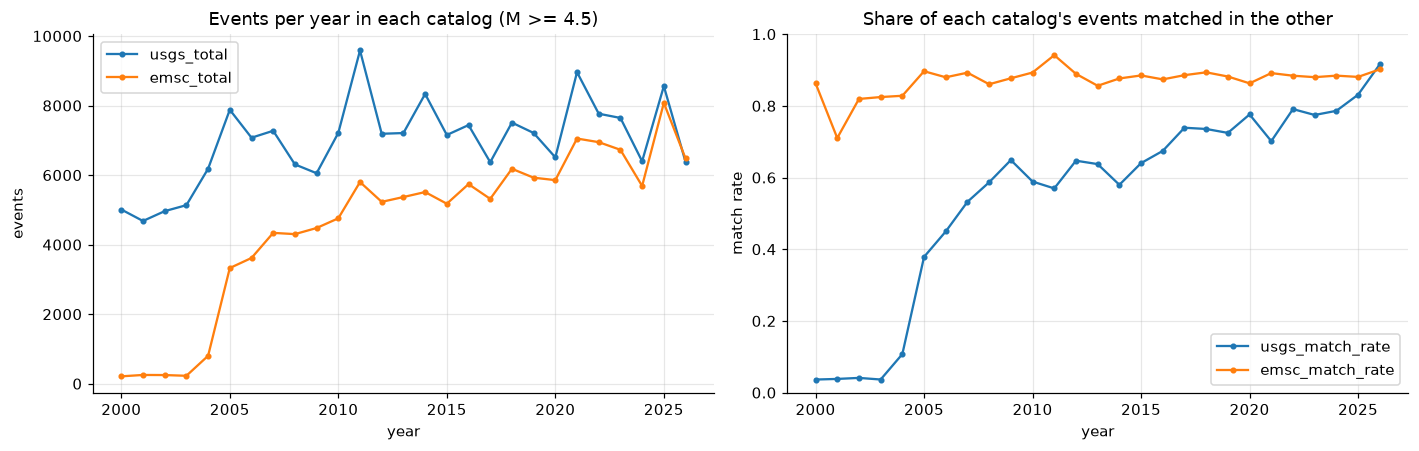

In [7]:
by_year = pd.crosstab(clean["year"], clean["source"])
for col in ["both", "usgs_only", "emsc_only"]:
    if col not in by_year:
        by_year[col] = 0
by_year["usgs_total"] = by_year["both"] + by_year["usgs_only"]
by_year["emsc_total"] = by_year["both"] + by_year["emsc_only"]
by_year["usgs_match_rate"] = by_year["both"] / by_year["usgs_total"].clip(lower=1)
by_year["emsc_match_rate"] = by_year["both"] / by_year["emsc_total"].clip(lower=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
by_year[["usgs_total", "emsc_total"]].plot(ax=ax[0], marker="o", ms=3)
ax[0].set_title("Events per year in each catalog (M >= 4.5)")
ax[0].set_xlabel("year"); ax[0].set_ylabel("events"); ax[0].legend(title="")

by_year[["usgs_match_rate", "emsc_match_rate"]].plot(ax=ax[1], marker="o", ms=3)
ax[1].set_title("Share of each catalog's events matched in the other")
ax[1].set_xlabel("year"); ax[1].set_ylabel("match rate"); ax[1].set_ylim(0, 1); ax[1].legend(title="")
save("02_coverage_by_year")

**How to read it:** the USGS catalog is stable over the whole period, while EMSC is sparse before about 2005 and keeps improving after that.
So the USGS-side match rate measures EMSC coverage, not matching quality. The EMSC-side match rate (the share of EMSC events that also exist in USGS) is flat after 2005, which shows the matching behaves the same in every year.
For this reason the USGS catalog is the base for all later analysis, and EMSC is used for cross-validation.

In [8]:
mm = clean.groupby("source")["depth_is_default"].mean().rename("share_depth_exactly_10km").to_frame()
display(mm.style.format("{:.1%}"))

,share_depth_exactly_10km
source,
both,34.8%
emsc_only,25.1%
usgs_only,34.4%


## 3. Depth

Events with depth exactly 10.0 km: 65,121 (34.6%)


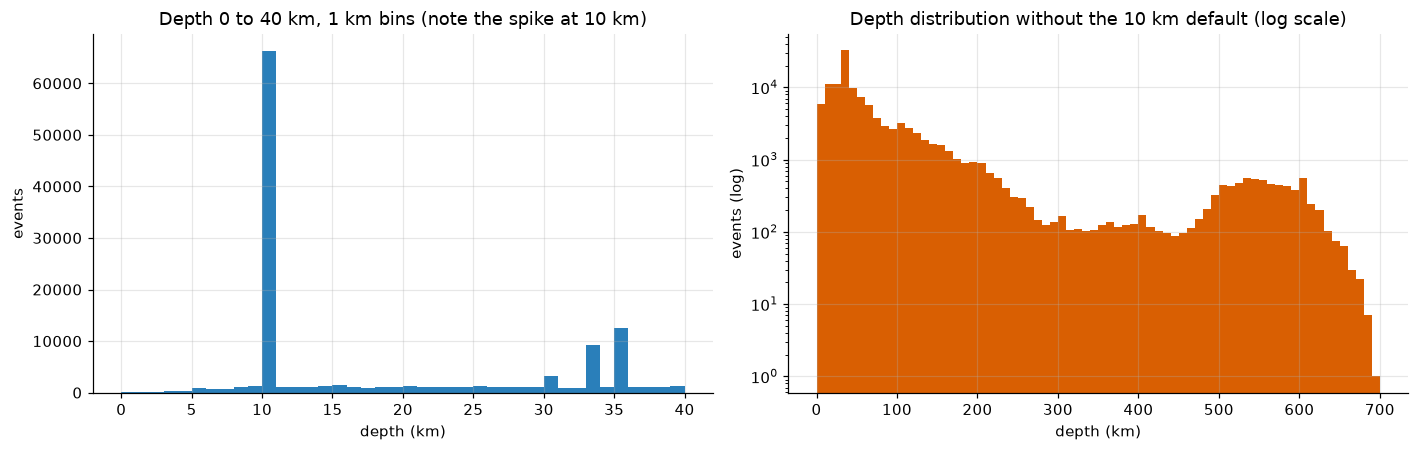

In [9]:
d = usgs["depth_km"].dropna()
share10 = (d == 10).mean()
print(f"Events with depth exactly 10.0 km: {(d == 10).sum():,} ({share10:.1%})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(d[(d >= 0) & (d <= 40)], bins=np.arange(0, 41, 1), color="#2a7fba")
ax[0].set_title("Depth 0 to 40 km, 1 km bins (note the spike at 10 km)")
ax[0].set_xlabel("depth (km)"); ax[0].set_ylabel("events")

ax[1].hist(d[(d != 10) & (d >= 0)], bins=np.arange(0, 701, 10), color="#d95f02")
ax[1].set_yscale("log")
ax[1].set_title("Depth distribution without the 10 km default (log scale)")
ax[1].set_xlabel("depth (km)"); ax[1].set_ylabel("events (log)")
save("03_depth_hist")

**Interpretation:** a huge share of events has a depth of exactly 10 km, while 9 km and 11 km are about 60 times rarer. This is not natural: it looks like a **default value** that agencies assign when the depth cannot be measured well.
Consequences: (1) every depth analysis is shown with and without these events, (2) for Project 2 we add a boolean feature `depth_is_default` next to `depth_km`.

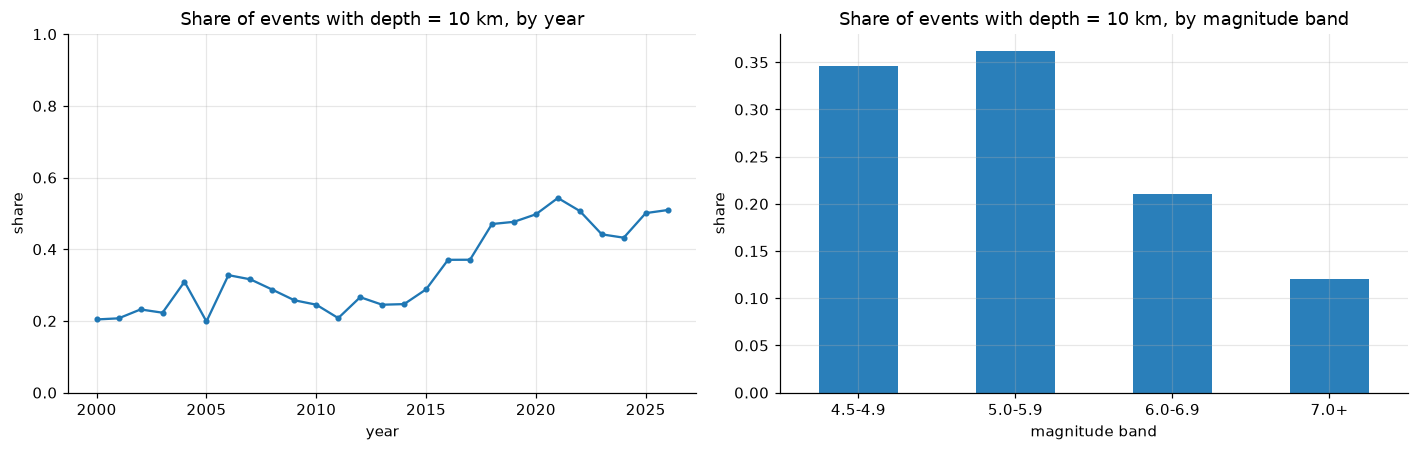

In [10]:
usgs["depth_is_default"] = usgs["depth_km"] == 10
usgs["mag_band"] = pd.cut(usgs["magnitude"], [0, 5.0, 6.0, 7.0, 10], right=False,
                          labels=["4.5-4.9", "5.0-5.9", "6.0-6.9", "7.0+"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
usgs.groupby("year")["depth_is_default"].mean().plot(ax=ax[0], marker="o", ms=3)
ax[0].set_title("Share of events with depth = 10 km, by year"); ax[0].set_ylim(0, 1)
ax[0].set_xlabel("year"); ax[0].set_ylabel("share")

usgs.groupby("mag_band", observed=True)["depth_is_default"].mean().plot.bar(ax=ax[1], color="#2a7fba")
ax[1].set_title("Share of events with depth = 10 km, by magnitude band")
ax[1].set_xlabel("magnitude band"); ax[1].set_ylabel("share"); ax[1].tick_params(axis="x", rotation=0)
save("03_depth_default_share")

In [11]:
real = usgs[~usgs["depth_is_default"] & usgs["depth_km"].notna()]
dclass = pd.cut(real["depth_km"], [-10, 70, 300, 800], labels=["shallow (<70 km)", "intermediate (70-300 km)", "deep (>300 km)"])
tab = dclass.value_counts(normalize=True).sort_index().rename("share").to_frame()
display(tab.style.format("{:.1%}"))

,share
depth_km,
shallow (<70 km),68.0%
intermediate (70-300 km),25.0%
deep (>300 km),7.0%


**Note:** the shallow / intermediate / deep split is computed **without** the 10 km events, because their true depth is unknown.

## 4. Gutenberg-Richter law

The law says $\log_{10} N(\ge M) = a - b\,M$: each step of one magnitude unit makes events about $10^{b}$ times rarer, and $b$ is typically close to 1.
We estimate $b$ with the Aki maximum-likelihood formula for binned magnitudes, $\hat b = \log_{10}(e) / (\bar M - (M_c - \Delta M/2))$ with $M_c = 4.5$ and $\Delta M = 0.1$, and the Shi and Bolt standard error.

Global b-value (M >= 4.5): 1.148 +/- 0.003   (n = 187,979)


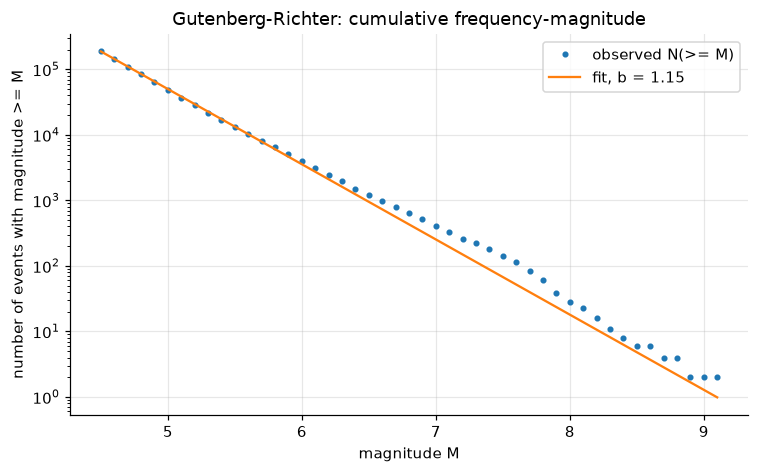

In [12]:
MC, DM = 4.5, 0.1
mags = usgs["magnitude"].dropna()
mags = mags[mags >= MC - 1e-9]


def b_value(m, mc=MC, dm=DM):
    m = np.asarray(m, dtype=float)
    n = len(m)
    mean = m.mean()
    b = np.log10(np.e) / (mean - (mc - dm / 2))
    se = 2.30 * b ** 2 * np.sqrt(((m - mean) ** 2).sum() / (n * (n - 1)))
    return b, se, n


b, se, n = b_value(mags)
print(f"Global b-value (M >= {MC}): {b:.3f} +/- {se:.3f}   (n = {n:,})")

grid = np.round(np.arange(MC, mags.max() + DM, DM), 1)
cum = np.array([(mags >= g - 1e-9).sum() for g in grid])
a = np.log10(cum[0]) + b * MC

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.semilogy(grid, cum, "o", ms=3, label="observed N(>= M)")
ax.semilogy(grid, 10 ** (a - b * grid), "-", label=f"fit, b = {b:.2f}")
ax.set_xlabel("magnitude M"); ax.set_ylabel("number of events with magnitude >= M")
ax.set_title("Gutenberg-Richter: cumulative frequency-magnitude")
ax.legend()
save("04_gutenberg_richter")

,period,events,b,se
0,2000-2004,25970,1.045,0.007
1,2005-2009,34587,1.070,0.006
2,2010-2014,39528,1.136,0.006
3,2015-2019,35682,1.221,0.007
4,2020-2026,52212,1.226,0.006


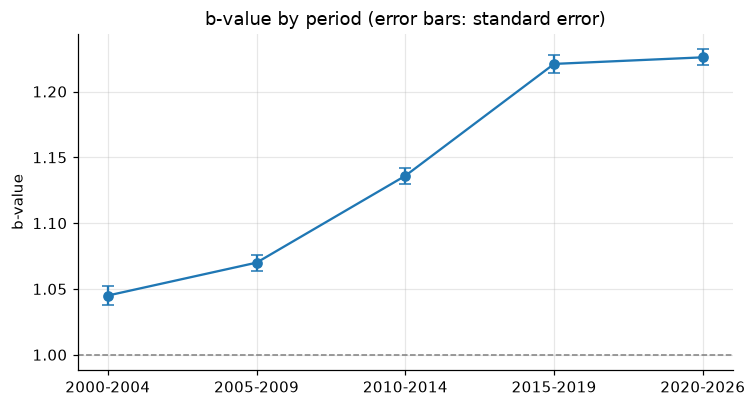

In [13]:
rows = []
for label, lo, hi in [("2000-2004", 2000, 2004), ("2005-2009", 2005, 2009), ("2010-2014", 2010, 2014),
                      ("2015-2019", 2015, 2019), ("2020-2026", 2020, 2026)]:
    m = usgs.loc[(usgs.year >= lo) & (usgs.year <= hi), "magnitude"].dropna()
    m = m[m >= MC - 1e-9]
    b_, se_, n_ = b_value(m)
    rows.append({"period": label, "events": n_, "b": round(b_, 3), "se": round(se_, 3)})
btab = pd.DataFrame(rows)
display(btab)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(btab["period"], btab["b"], yerr=btab["se"], fmt="o-", capsize=4)
ax.axhline(1.0, color="gray", ls="--", lw=1)
ax.set_ylabel("b-value"); ax.set_title("b-value by period (error bars: standard error)")
save("04_b_value_by_period")

**What to look for:** a b-value near 1 means the catalog behaves like a normal earthquake catalog.
If $b$ changes a lot between periods, check whether it is a real effect or a catalog-completeness effect (for example a change in how magnitudes are reported).
The estimate depends on the completeness magnitude $M_c$, so we keep the same $M_c = 4.5$ for all periods.

In [14]:
# Does b depend on depth? (10 km default events removed, since their depth is unknown)
rows = []
for label, lo, hi in [("shallow < 70 km", -10, 70), ("intermediate 70-300 km", 70, 300), ("deep > 300 km", 300, 800)]:
    sub = usgs[(usgs.depth_km >= lo) & (usgs.depth_km < hi) & (usgs.depth_km != 10)]["magnitude"].dropna()
    sub = sub[sub >= MC - 1e-9]
    if len(sub) > 50:
        b_, se_, n_ = b_value(sub)
        rows.append({"depth class": label, "events": n_, "b": round(b_, 3), "se": round(se_, 3)})
display(pd.DataFrame(rows))

,depth class,events,b,se
0,shallow < 70 km,83481,1.069,0.004
1,intermediate 70-300 km,30674,1.313,0.008
2,deep > 300 km,8703,1.220,0.017


## 5. Time patterns and aftershocks

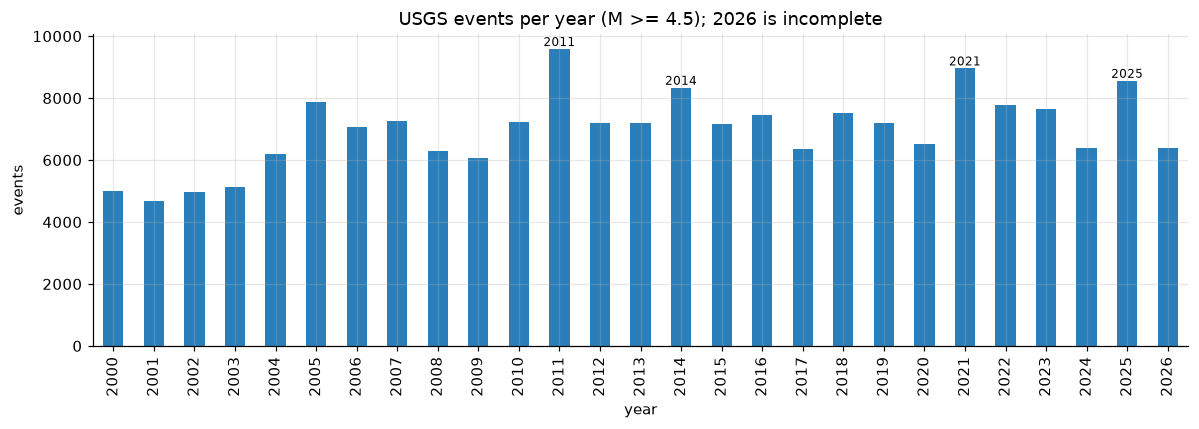

Top years: {2011: 9584, 2021: 8959, 2025: 8558, 2014: 8333}


In [15]:
yearly = usgs.groupby("year").size()
big_years = yearly.sort_values(ascending=False).head(4)

fig, ax = plt.subplots(figsize=(11, 4))
yearly.plot.bar(ax=ax, color="#2a7fba")
for yr in big_years.index:
    ax.annotate(str(yr), (list(yearly.index).index(yr), yearly[yr]), ha="center", va="bottom", fontsize=8)
ax.set_title("USGS events per year (M >= 4.5); 2026 is incomplete")
ax.set_xlabel("year"); ax.set_ylabel("events")
save("05_events_per_year")

print("Top years:", big_years.to_dict())

In [16]:
top = usgs.nlargest(10, "magnitude")[["event_time", "magnitude", "mag_type", "place", "depth_km"]].copy()
top["event_time"] = top["event_time"].dt.strftime("%Y-%m-%d %H:%M")
display(top.reset_index(drop=True))

,event_time,magnitude,mag_type,place,depth_km
0,2004-12-26 00:58,9.1,mw,2004 Sumatra - Andaman Islands Earthquake,30.0
1,2011-03-11 05:46,9.1,mww,"2011 Great Tohoku Earthquake, Japan",29.0
2,2010-02-27 06:34,8.8,mww,"2010 Maule, Chile Earthquake",22.9
3,2025-07-29 23:24,8.8,mww,"2025 Kamchatka Peninsula, Russia Earthquake",35.0
4,2005-03-28 16:09,8.6,mww,"78 km WSW of Singkil, Indonesia",30.0
5,2012-04-11 08:38,8.6,mw,2012 Wharton Basin Earthquake,20.0
6,2001-06-23 20:33,8.4,mww,"6 km SSW of Atico, Peru",33.0
7,2007-09-12 11:10,8.4,mww,"122 km SW of Bengkulu, Indonesia",34.0
8,2006-11-15 11:14,8.3,mwc,2006 Kuril Islands Earthquake,10.0
9,2013-05-24 05:44,8.3,mww,2013 Sea of Okhotsk Earthquake,598.1


**Interpretation:** years with a very high count usually follow a huge earthquake whose aftershocks are all counted in the same catalog.
Check the table of the largest events against the busiest years. This is the link to Project 3, where we try to estimate the number of aftershocks.

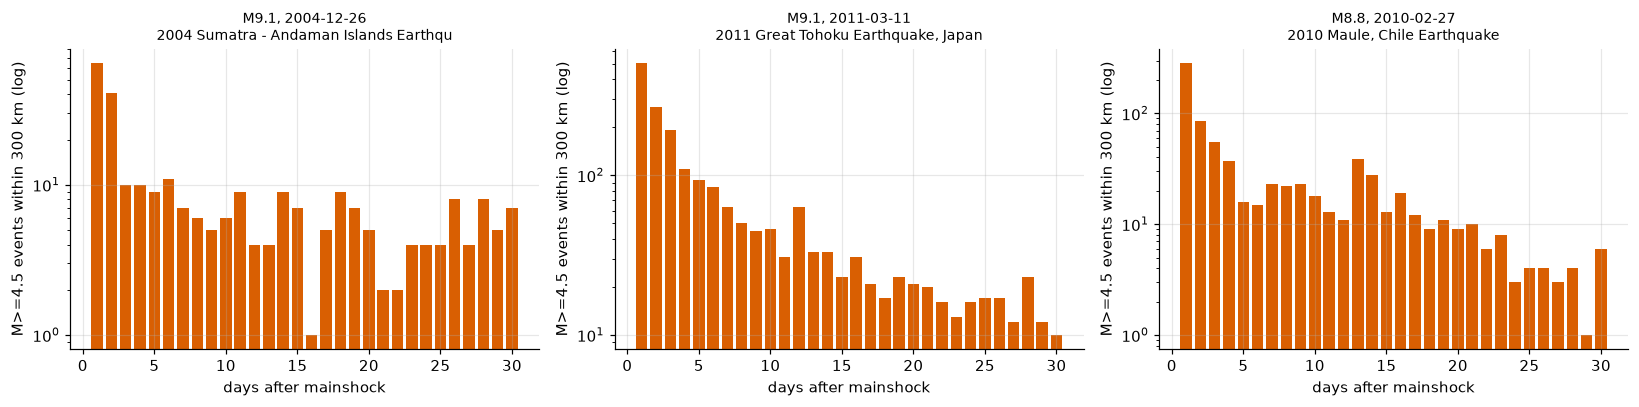

In [17]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlam = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlam / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


mains = usgs.nlargest(3, "magnitude")
fig, axes = plt.subplots(1, len(mains), figsize=(5 * len(mains), 3.8), squeeze=False)
for ax, (_, ms) in zip(axes[0], mains.iterrows()):
    dist = haversine_km(ms.latitude, ms.longitude, usgs["latitude"].to_numpy(), usgs["longitude"].to_numpy())
    days = (usgs["event_time"] - ms.event_time).dt.total_seconds().to_numpy() / 86400
    sel = (dist <= 300) & (days > 0) & (days <= 30) & (usgs["event_id"].to_numpy() != ms.event_id)
    counts = np.bincount(np.floor(days[sel]).astype(int), minlength=30)[:30]
    ax.bar(np.arange(1, 31), counts, color="#d95f02")
    if counts.sum() > 0:
        ax.set_yscale("log")
    ax.set_title(f"M{ms.magnitude:.1f}, {ms.event_time:%Y-%m-%d}\n{str(ms.place)[:38]}", fontsize=9)
    ax.set_xlabel("days after mainshock"); ax.set_ylabel("M>=4.5 events within 300 km (log)")
save("05_aftershock_decay")

**What to look for:** the daily count drops quickly after the mainshock and then slowly, which is the Omori law (rate proportional to 1/(t + c)).
This is only an exploration with a simple radius, and the proper definition of an aftershock (radius, time window, magnitude threshold) will be fixed in Project 3.

C:\Users\Tech Emporium\AppData\Local\Temp\ipykernel_18040\1372187213.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  usgs.groupby(usgs.event_time.dt.dayofweek).size().plot.bar(ax=ax[2], color="#2a7fba")


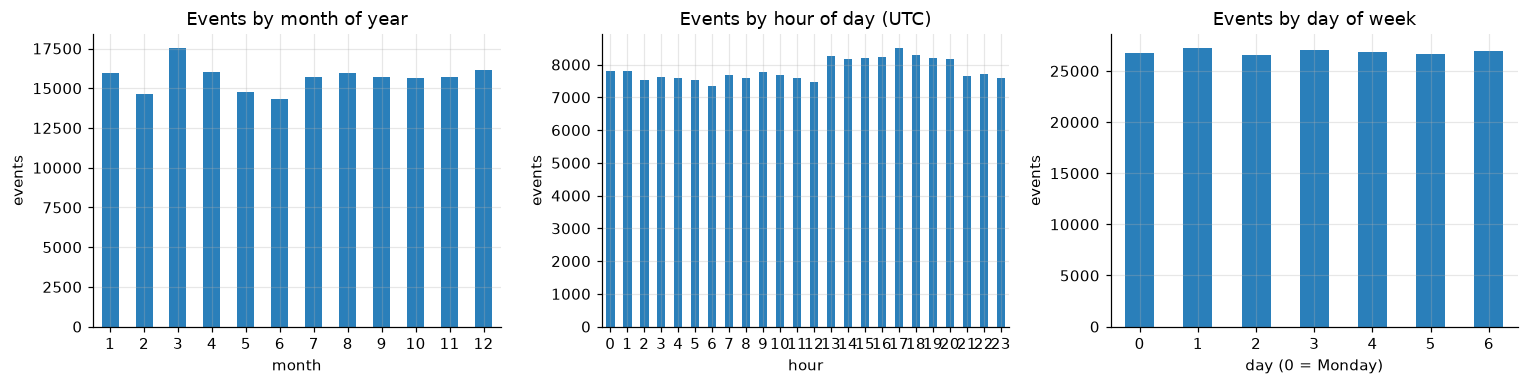

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
usgs.groupby(usgs.event_time.dt.month).size().plot.bar(ax=ax[0], color="#2a7fba")
ax[0].set_title("Events by month of year"); ax[0].set_xlabel("month")
usgs.groupby(usgs.event_time.dt.hour).size().plot.bar(ax=ax[1], color="#2a7fba")
ax[1].set_title("Events by hour of day (UTC)"); ax[1].set_xlabel("hour")
usgs.groupby(usgs.event_time.dt.dayofweek).size().plot.bar(ax=ax[2], color="#2a7fba")
ax[2].set_title("Events by day of week"); ax[2].set_xlabel("day (0 = Monday)")
for a_ in ax:
    a_.set_ylabel("events"); a_.tick_params(axis="x", rotation=0)
save("05_seasonality_sanity")

**Sanity check:** earthquakes do not follow the calendar, so month, hour and weekday should look roughly flat.
If one bar is very different, that points to a data or time-zone problem and not to a real pattern. All timestamps are stored in UTC.

---
**Next (Part 2):** world map and regions, Pakistan and Hindu Kush focus, USGS vs EMSC magnitude and depth comparison for matched events, summary of findings.